# D07 · Explain the model in the right units
Inspect signed TreeSHAP contributions, reconstruct raw log-odds, compare a recorded feature edit, and see how duplicated inputs undermine a unique attribution story.
**Prerequisites:** basic Python and the [learning guide](../docs/LEARNING_GUIDE.md).
**Evidence boundary:** the charts read the recorded October 26, 2026 experiments by default. Running this notebook recomputes plots and teaching calculations; it does not retrain a model or run new model inference. Illustrative examples below are labeled separately. The [notebook guide](README.md) explains setup, provenance, and how to export your own completed runs.

## Load the evidence
Run all cells in order. The loader prints the run IDs, dates, seeds and scope. A custom export does not automatically rewrite the historical interpretation in this lesson.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# Works when Jupyter starts in the repository root or notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/lab.py").is_file() and (p / "src/ml_training").is_dir())
for folder in [ROOT / "notebooks", ROOT / "src"]:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from lab import load_demo, style, grouped_bars
style()

# None uses the compact checked-in snapshot. To inspect a new export, set an
# explicit path, e.g. ROOT / "artifacts/my-notebook-results.json". Missing files fail.
SNAPSHOT_PATH = None
d = load_demo("D07", SNAPSHOT_PATH)

D07 | recorded experiment data | recorded_results.json
Recorded local educational experiments. Inspect run dates, seeds and source manifests before comparing results. No production or physical-device validation.
Run: artifacts/explainability/local-s41-20261026T163345Z-d633f1 | recorded: 20261026T163345Z | seed: 41


## The concept
TreeSHAP decomposes a chosen model output relative to a background population: $f(x) = E[f(X)] + \sum_i \phi_i$. Here the output is **raw log-odds** under interventional perturbation, not calibrated probability. Applying the sigmoid reconstructs the uncalibrated probability; a separate calibrator can change it.
Additivity is a fidelity check on an explanation of this model. It does not validate the model, identify causes, or prove that changing a real-world variable produces the same outcome.

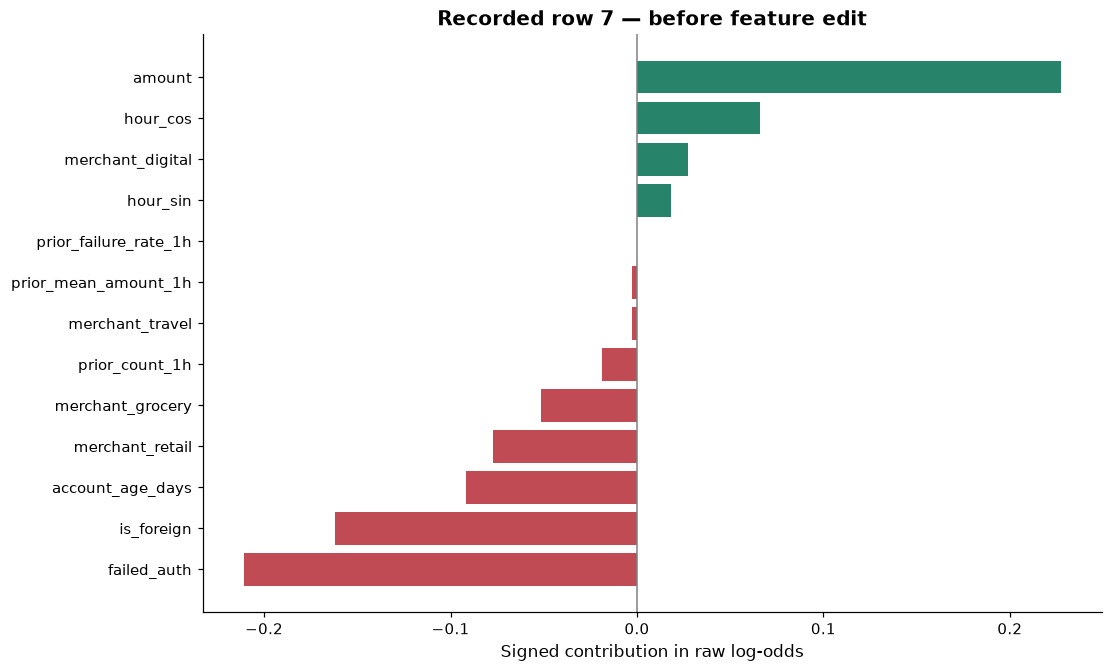

Base -4.368875 + contributions -0.278874 = -4.647749
Residual against saved raw score: 6.54712563274984e-07
Sigmoid of raw score: 0.009492183143677061
Separately calibrated probability: 0.011997347697615623


In [2]:
edit = d['feature_edit']
which = 'before'  # Try 'after' to inspect the recorded amount=450 edit.
row = edit[which]
contributions = row['contributions_log_odds']
names = sorted(contributions, key=lambda k: contributions[k])
values = np.array([contributions[k] for k in names])
fig, ax = plt.subplots(figsize=(10, 6), layout='constrained')
ax.barh([n.replace('numeric__', '').replace('category__', '') for n in names], values,
        color=['#c04b55' if v < 0 else '#28836b' for v in values])
ax.axvline(0, color='gray', lw=1)
ax.set(xlabel='Signed contribution in raw log-odds', title=f'Recorded row 7 — {which} feature edit')
plt.show()
reconstructed = row['base_log_odds'] + sum(contributions.values())
print(f'Base {row["base_log_odds"]:.6f} + contributions {sum(contributions.values()):.6f} = {reconstructed:.6f}')
print('Residual against saved raw score:', abs(reconstructed - row['raw_log_odds']))
print('Sigmoid of raw score:', 1/(1 + np.exp(-reconstructed)))
print('Separately calibrated probability:', row['calibrated_probability'])
assert abs(reconstructed - row['raw_log_odds']) < 1e-5

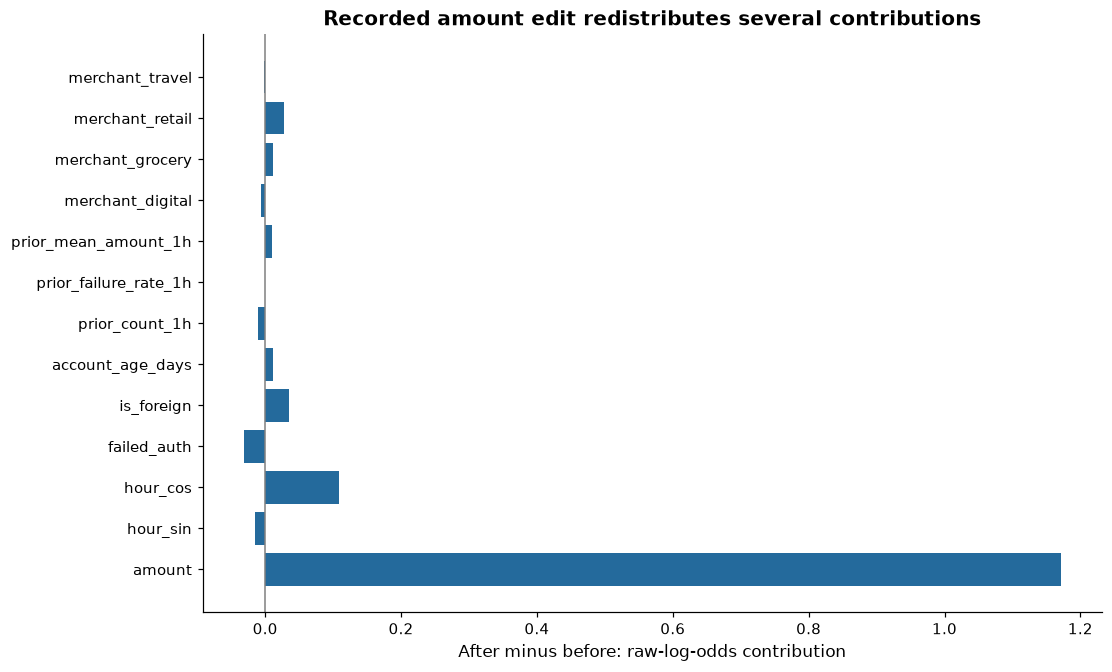

In [3]:
names = list(edit['before']['contributions_log_odds'])
deltas = [edit['after']['contributions_log_odds'][n] - edit['before']['contributions_log_odds'][n] for n in names]
fig, ax = plt.subplots(figsize=(10, 6), layout='constrained')
ax.barh([n.replace('numeric__', '').replace('category__', '') for n in names], deltas)
ax.axvline(0, color='gray', lw=1)
ax.set(xlabel='After minus before: raw-log-odds contribution', title='Recorded amount edit redistributes several contributions')
plt.show()

### A counterexample to a causal reading
In this separate recorded synthetic experiment, two input columns are identical. Reversing their order changes which column the trained trees use; predictions remain identical. Feature attribution follows the fitted model, so it can move between duplicate variables.

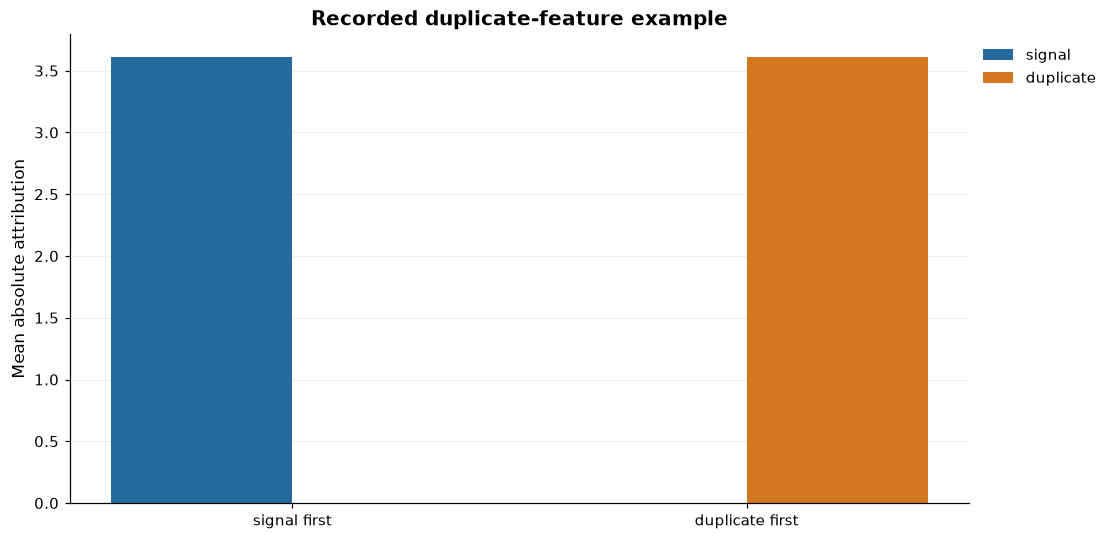

Maximum probability difference: 0.0


In [4]:
correlated = d['correlated_features']
grouped_bars(['signal first', 'duplicate first'], {
    feature: [v['mean_abs_attribution'][feature] for v in correlated['variants']]
    for feature in ['signal', 'duplicate']
}, title='Recorded duplicate-feature example', ylabel='Mean absolute attribution', fraction=False)
plt.show()
print('Maximum probability difference:', correlated['max_probability_difference'])

**Try it:** change `which` and rerun the first plot. Explain why the sigmoid result and calibrated probability differ. To change an arbitrary feature and recompute SHAP with a loaded model, use the D07 CLI exercise in the tutorial; the snapshot only contains this one before/after edit. The conditional edit holds history fixed and is not a causal intervention.

## What you learned and when to use it
Match an explanation to its audience, output units and reference population. Interpretable predictors, permutation importance and response curves answer related but different questions. Causal remedies require evidence beyond a local attribution plot.
**Architecture exercise:** state a quality floor, a simpler alternative, and the evidence that would make you reject this approach. Compare your answer with the [decision guide](../docs/ARCHITECTURE_DECISION_GUIDE.md#d07--explain-predictions).
**Train or run the actual model:** follow the [D07 tutorial](../docs/CPU_DEMOS.md#d07-inspect-and-change-an-explanation). Training stays in its existing locked environment; this notebook stays light enough to run without model downloads.
[All visual lessons](README.md) · [Production tradeoffs](../docs/PRODUCTION_TRADEOFFS.md)